# 03 · Deep Knowledge Tracing (DKT) on ASSISTments 2009

Part of: *AI-Driven Personalised Learning Path for WAEC/JAMB Mathematics Using Knowledge Tracing*

What this notebook does:

1. Cleans the data and splits it by student **exactly as notebook 01 does**, and checks that the shared code hasn't drifted.
2. Re-fits notebook 01's baselines and BKT, so every model is scored on the same rows.
3. Trains DKT (an LSTM), choosing settings on a validation set of *training* students.
4. Scores the test students once, with AUC, RMSE, accuracy, log-loss and a confidence interval.
5. Checks whether the model **behaves** well enough to choose questions, which AUC does not tell you.
6. Exports ONNX + JSON + a small loader that FastAPI can use **without PyTorch**, and registers the model in MLflow.

**Run it from `ml/`** with Restart & Run All. It takes about 10 minutes on a laptop CPU.

**Getting the data:** download the *corrected* file from the [official page](https://sites.google.com/site/assistmentsdata/home/2009-2010-assistment-data/skill-builder-data-2009-2010) ([direct link](https://drive.google.com/file/d/1NNXHFRxcArrU0ZJSb9BIL56vmUt5FhlE/view)) to `ml/data/skill_builder_data_corrected_collapsed.csv`. Its [terms of use](https://sites.google.com/site/assistmentsdata/termsofuseforusingdata) say not to redistribute it, to acknowledge ASSISTments, and to publish your code and algorithms. This notebook prints only aggregates, never student rows.

## 0 · Setup

In [1]:
# Python 3.12+. These are the versions this notebook was tested with:
# pip install torch==2.15.0 numpy==2.5.5 pandas==3.1.1 scikit-learn==1.9.1 scipy==1.18.1 matplotlib==3.11.2 \
#             mlflow==3.18.0 onnx==1.23.2 onnxscript==0.7.2 onnxruntime==1.32.0 ipykernel
import os
os.environ.setdefault("MLFLOW_DISABLE_TELEMETRY", "true")   # must be set before importing mlflow
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
os.environ.setdefault("GIT_PYTHON_REFRESH", "quiet")

import ast, copy, hashlib, inspect, json, logging, shutil, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score, mean_squared_error, accuracy_score, log_loss
import torch
from torch import nn
import mlflow, mlflow.onnx
import onnx, onnxruntime

warnings.filterwarnings("ignore", category=RuntimeWarning)
for name in ("mlflow", "alembic", "torch.onnx", "onnxscript", "onnx_ir"):
    logging.getLogger(name).setLevel(logging.ERROR)

# ---- must match notebook 01 (checked below) ------------------------------
SEED = 42
DATA_PATH = Path("data/skill_builder_data_corrected_collapsed.csv")
MIN_INTERACTIONS_PER_SKILL = 50
TEST_FRACTION = 0.2

# ---- DKT only ------------------------------------------------------------
OUT_DIR = Path("artifacts/dkt")
VAL_FRACTION = 0.15       # share of TRAINING students held back for choosing settings
MAX_EPOCHS = 40
PATIENCE = 5              # stop after this many epochs without a better validation AUC
BATCH_SIZE = 32           # students per batch
GRID = [
    dict(emb_dim=64,  hidden=64,  dropout=0.3, lr=0.003),
    dict(emb_dim=64,  hidden=128, dropout=0.5, lr=0.003),
    dict(emb_dim=100, hidden=128, dropout=0.4, lr=0.002),
    dict(emb_dim=128, hidden=200, dropout=0.5, lr=0.001),
]
EXPERIMENT = "kt-waec-jamb"          # same experiment as notebook 01
REGISTERED_NAME = "dkt-assist09"

# CPU keeps runs reproducible and is fast enough for a dataset this size.
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
if not DATA_PATH.exists():
    raise FileNotFoundError(f"{DATA_PATH} not found. Run from ml/ and see 'Getting the data' above.")
print(f"torch {torch.__version__} | mlflow {mlflow.__version__} | onnxruntime {onnxruntime.__version__}")

torch 2.15.0+cpu | mlflow 3.18.0 | onnxruntime 1.32.0


## 1 · Same data, same split, same metrics

The next cell is **copied from notebook 01**. The cell after it compares the two notebooks' code and stops with an error if they differ, because a comparison between models scored on different rows is meaningless.

In [2]:
def clean(df):
    n0 = len(df)
    df = df.dropna(subset=["skill_name"]).copy()
    if "original" in df.columns:
        df = df[df["original"] == 1]
    df = df[df["correct"].isin([0, 1])]
    df["correct"] = df["correct"].astype(int)
    df["skill_name"] = df["skill_name"].astype(str).str.strip()
    df = df.drop_duplicates(subset=["order_id", "skill_name"])
    counts = df["skill_name"].value_counts()
    df = df[df["skill_name"].isin(counts[counts >= MIN_INTERACTIONS_PER_SKILL].index)]
    df = df.sort_values("order_id").reset_index(drop=True)
    print(f"rows {n0:,} -> {len(df):,}")
    return df[["order_id", "user_id", "skill_name", "correct"]]

def evaluate(y, p, name):
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6)
    return dict(model=name, auc=roc_auc_score(y, p),
                rmse=mean_squared_error(y, p) ** 0.5,
                acc=accuracy_score(y, p >= 0.5), logloss=log_loss(y, p))

BOUNDS = dict(prior=(0.01, 0.99), learn=(0.01, 0.99), guess=(0.01, 0.30), slip=(0.01, 0.40))
NAMES = list(BOUNDS)

def to_matrix(df_skill):
    # one row per student, columns = their attempts in time order (padded)
    seqs = [g.values for _, g in df_skill.groupby("user_id", sort=False)["correct"]]
    T = max(len(s) for s in seqs)
    obs = np.zeros((len(seqs), T), dtype=np.int8); mask = np.zeros((len(seqs), T), bool)
    for i, s in enumerate(seqs):
        obs[i, :len(s)] = s; mask[i, :len(s)] = True
    return obs, mask

def bkt_forward(prior, learn, guess, slip, obs, mask, forget=0.0):
    # returns P(correct) BEFORE each observation (S x T) and final P(known) per student
    p_known = np.full(obs.shape[0], prior)
    preds = np.zeros(obs.shape)
    for t in range(obs.shape[1]):
        p_c = p_known * (1 - slip) + (1 - p_known) * guess
        preds[:, t] = p_c
        o = obs[:, t] == 1
        post = np.where(o, p_known * (1 - slip) / p_c, p_known * slip / (1 - p_c))
        nxt = post * (1 - forget) + (1 - post) * learn
        p_known = np.where(mask[:, t], nxt, p_known)
    return preds, p_known

def nll(theta, obs, mask):
    preds, _ = bkt_forward(*theta, obs, mask)
    p = np.clip(preds[mask], 1e-9, 1 - 1e-9); y = obs[mask]
    return -np.sum(y * np.log(p) + (1 - y) * np.log(1 - p))

def fit_skill(df_skill, restarts=3, seed=SEED):
    obs, mask = to_matrix(df_skill)
    r = np.random.default_rng(seed); best = None
    for _ in range(restarts):
        x0 = [r.uniform(*BOUNDS[n]) for n in NAMES]
        res = minimize(nll, x0, args=(obs, mask), method="L-BFGS-B", bounds=[BOUNDS[n] for n in NAMES])
        if best is None or res.fun < best.fun:
            best = res
    return dict(zip(NAMES, map(float, best.x)))

In [3]:
def definitions(source, wanted):
    """Map each wanted function/constant name to its syntax tree (ignores comments and spacing)."""
    found = {}
    for node in ast.parse(source).body:
        if isinstance(node, ast.FunctionDef) and node.name in wanted:
            found[node.name] = ast.dump(node)
        elif isinstance(node, ast.Assign):
            for target in node.targets:
                if isinstance(target, ast.Name) and target.id in wanted:
                    found[target.id] = ast.dump(node.value)
    return found

SHARED_FUNCS = [clean, evaluate, to_matrix, bkt_forward, nll, fit_skill]
SHARED_CONSTS = dict(SEED=SEED, MIN_INTERACTIONS_PER_SKILL=MIN_INTERACTIONS_PER_SKILL,
                     TEST_FRACTION=TEST_FRACTION, BOUNDS=BOUNDS)

nb01 = json.loads(Path("01_bkt_starter.ipynb").read_text(encoding="utf-8"))
theirs = {}
for cell in nb01["cells"]:
    src = "".join(cell["source"])
    if cell["cell_type"] == "code":
        theirs.update(definitions(src, {f.__name__ for f in SHARED_FUNCS} | set(SHARED_CONSTS)))

drift = [f.__name__ for f in SHARED_FUNCS
         if definitions(inspect.getsource(f), {f.__name__})[f.__name__] != theirs.get(f.__name__)]
# BOUNDS is written as dict(...), so compare it as source; the others are plain literals.
expected = {k: ast.dump(ast.parse(repr(v), mode="eval").body) for k, v in SHARED_CONSTS.items() if k != "BOUNDS"}
expected["BOUNDS"] = ast.dump(ast.parse(
    "dict(" + ", ".join(f"{k}={v!r}" for k, v in BOUNDS.items()) + ")", mode="eval").body)
drift += [k for k, v in expected.items() if theirs.get(k) != v]
assert not drift, f"These differ from notebook 01: {drift}. Make them identical before comparing models."
print("shared code and constants match notebook 01")

shared code and constants match notebook 01


In [4]:
raw = pd.read_csv(DATA_PATH, encoding="latin-1", low_memory=False)
DATA_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
data = clean(raw)

# One row must be one answer. In the non-collapsed file a two-skill question is two rows with the
# same answer, so an LSTM would read the first and "predict" the second: a well-known leak that
# inflates DKT's AUC on this dataset (Xiong et al., 2016).
assert data.order_id.is_unique, "Repeated order_id: use the corrected *collapsed* CSV, or DKT will leak answers."

gss = GroupShuffleSplit(n_splits=1, test_size=TEST_FRACTION, random_state=SEED)
tr_idx, te_idx = next(gss.split(data, groups=data["user_id"]))
train, test = data.iloc[tr_idx].copy(), data.iloc[te_idx].copy()
assert set(train.user_id).isdisjoint(test.user_id)

SPLIT_SHA256 = hashlib.sha256(",".join(map(str, sorted(test.user_id.unique()))).encode()).hexdigest()
print(f"students {data.user_id.nunique():,} | skills {data.skill_name.nunique()}")
print(f"train rows {len(train):,} ({train.user_id.nunique()} students) | "
      f"test rows {len(test):,} ({test.user_id.nunique()} students)")
print(f"data sha256 {DATA_SHA256[:16]} | test-student sha256 {SPLIT_SHA256[:16]}")

rows 346,860 -> 251,165
students 4,138 | skills 90
train rows 199,037 (3310 students) | test rows 52,128 (828 students)
data sha256 162ef8d2d28bcbfe | test-student sha256 725d63299707f207


### Preprocessing choices to report in the methods section

| choice | what it means here |
|---|---|
| drop null `skill_name` | also drops some rows that *do* have a `skill_id` but no name (counted below) |
| `original == 1` | no scaffolding sub-questions |
| `correct` in {0, 1} | first attempt; asking for a hint counts as wrong |
| dedupe on (`order_id`, `skill_name`) | removes nothing in the corrected file |
| drop skills with < 50 rows | counted on all students before the split, as in notebook 01 |
| sort by `order_id` | chronological |
| **multi-skill questions** | one row, labelled with **one** skill name |

The last row differs from what notebook 01's text says ("counts once per skill"). In the collapsed file `skill_id` is joined (for example `1_13`) but `skill_name` holds only one of those names (Box and Whisker, with Median lost). Both models see the same labels, so the comparison is fair, but remember it when building `topic_skill_map.csv`.

In [5]:
kept = raw[raw.order_id.isin(data.order_id)]
print(f"rows with a skill_id but no skill_name (dropped): {(raw.skill_id.notna() & raw.skill_name.isna()).sum():,}")
print(f"kept rows that are multi-skill but carry one name: "
      f"{kept.skill_id.astype(str).str.contains('_').mean():.1%}")
del raw, kept

rows with a skill_id but no skill_name (dropped): 8,515
kept rows that are multi-skill but carry one name: 17.8%


## 2 · Baselines and BKT on the same rows
These should equal notebook 01's numbers when it is run with `USE_SYNTHETIC = False`.

In [6]:
y_test = test["correct"].values
skill_mean = train.groupby("skill_name").correct.mean()
test_preds = {
    "global mean": np.full(len(test), train.correct.mean()),
    "per-skill mean": test.skill_name.map(skill_mean).fillna(train.correct.mean()).values,
}

t0 = time.time()
bkt_params = {s: fit_skill(g) for s, g in train.groupby("skill_name")}
bkt_default = {n: float(np.median([p[n] for p in bkt_params.values()])) for n in NAMES}

def predict_bkt_online(df):
    """Replay answers in time order, as the app will: predict first, then update."""
    p_known, out = {}, []
    for user, skill, correct in zip(df.user_id, df.skill_name, df.correct):
        p = bkt_params.get(skill, bkt_default)
        k = p_known.get((user, skill), p["prior"])
        p_c = k * (1 - p["slip"]) + (1 - k) * p["guess"]
        post = k * (1 - p["slip"]) / p_c if correct else k * p["slip"] / (1 - p_c)
        p_known[user, skill] = post + (1 - post) * p["learn"]
        out.append(p_c)
    return np.array(out)

test_preds["BKT (NumPy, from scratch)"] = predict_bkt_online(test)
print(f"BKT fitted in {time.time() - t0:.0f}s")
pd.DataFrame([evaluate(y_test, p, name) for name, p in test_preds.items()]).round(4)

BKT fitted in 40s


,model,auc,rmse,acc,logloss
0,global mean,0.5000,0.4770,0.6506,0.6475
1,per-skill mean,0.6198,0.4668,0.6577,0.6260
2,"BKT (NumPy, from scratch)",0.7195,0.4404,0.7115,0.5727


## 3 · How DKT works

BKT keeps one number per skill, and the skills never affect each other. **DKT** (Piech et al., 2015) reads the student's whole history with one neural network, so success on *Equation Solving* can raise its estimate for *Solving for a variable*.

```
position       0          1                 2                 3
input          START      (skill₀, ans₀)    (skill₁, ans₁)    (skill₂, ans₂)
                 │          │                 │                 │
               LSTM ─────► LSTM ───────────► LSTM ───────────► LSTM      ─► hidden state = memory
                 │          │                 │                 │
output         P(correct) for EVERY skill, at every position
we score       skill₀     skill₁            skill₂            skill₃     (only the skill actually asked)
```

The vocabulary, if you come from web development:

- **Interaction ID:** each (skill, right/wrong) pair becomes an integer: `0` is START, otherwise `1 + 2*skill + correct`.
- **Embedding:** a lookup table from that integer to a learned vector.
- **LSTM:** a reducer, `state = f(state, event)`, where `f` is learned. The state summarises the history so far.
- **Linear + sigmoid:** turns the state into one probability per skill.
- **Loss:** binary cross-entropy (log-loss), on the skill that was asked.
- **Dropout:** randomly blanks part of the state during training, to reduce overfitting.
- **Epoch:** one pass over all training students.

**The golden rule:** the prediction for answer *t* may use answers before *t* only. The input is shifted right by one to guarantee this, and a test below proves it. START also lets DKT predict a student's very first answer, as BKT does. Many DKT implementations skip that answer, which would make the comparison unfair.

In [7]:
SKILLS = sorted(train.skill_name.unique())
SKILL_TO_IDX = {s: i for i, s in enumerate(SKILLS)}
K = len(SKILLS)
assert set(test.skill_name) <= set(SKILLS), "A test skill never appears in training, so DKT has no output for it."

def to_sequences(df):
    """One (rows, skills, answers) triple per student. `rows` are positions in df, to put predictions back."""
    skill = df.skill_name.map(SKILL_TO_IDX).to_numpy(np.int64)
    correct = df.correct.to_numpy(np.int64)
    return [(rows, skill[rows], correct[rows])
            for rows in df.groupby("user_id", sort=False).indices.values()]

def make_batches(seqs, batch_size=BATCH_SIZE):
    """Pad students of similar length together. Histories are never truncated."""
    seqs = sorted(seqs, key=lambda s: len(s[0]))
    batches = []
    for i in range(0, len(seqs), batch_size):
        chunk = seqs[i:i + batch_size]
        shape = (len(chunk), max(len(s[0]) for s in chunk))
        inputs, skills, rows = (np.zeros(shape, np.int64) for _ in range(3))
        answers, mask = np.zeros(shape, np.float32), np.zeros(shape, bool)
        for j, (r, s, c) in enumerate(chunk):
            n = len(r)
            rows[j, :n], skills[j, :n], answers[j, :n], mask[j, :n] = r, s, c, True
            inputs[j, 1:n] = 1 + 2 * s[:-1] + c[:-1]     # shifted right: position 0 stays START
        batches.append(dict(inputs=torch.from_numpy(inputs), skills=torch.from_numpy(skills),
                            answers=torch.from_numpy(answers), mask=torch.from_numpy(mask),
                            rows=torch.from_numpy(rows)))
    return batches

class DKT(nn.Module):
    def __init__(self, n_skills, emb_dim, hidden, dropout):
        super().__init__()
        self.embed = nn.Embedding(1 + 2 * n_skills, emb_dim)
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.out = nn.Linear(hidden, n_skills)

    def forward(self, interactions):                     # (students, time)
        state, _ = self.lstm(self.embed(interactions))   # (students, time, hidden)
        return self.out(self.dropout(state))             # (students, time, skills), before the sigmoid

def asked_skill_logits(model, batch):
    """Keep only the output for the skill that was asked at each real (non-padding) position."""
    logits = model(batch["inputs"]).gather(2, batch["skills"].unsqueeze(-1)).squeeze(-1)
    return logits[batch["mask"]]

def train_epoch(model, optimiser, batches, rng):
    model.train()                                        # dropout on
    total = n = 0
    for i in rng.permutation(len(batches)):
        batch = batches[i]
        target = batch["answers"][batch["mask"]]
        loss = nn.functional.binary_cross_entropy_with_logits(asked_skill_logits(model, batch), target)
        optimiser.zero_grad()                            # forget the previous batch's gradients
        loss.backward()                                  # which way should each weight move?
        nn.utils.clip_grad_norm_(model.parameters(), 5.0)  # long sequences can give huge gradients
        optimiser.step()                                 # move them
        total += loss.item() * len(target); n += len(target)
    return total / n

@torch.no_grad()
def predict_dkt(model, batches, n_rows):
    """P(correct) for every row, in the DataFrame's own row order."""
    model.eval()                                         # dropout off
    out = np.full(n_rows, np.nan)
    for batch in batches:
        out[batch["rows"][batch["mask"]].numpy()] = torch.sigmoid(asked_skill_logits(model, batch)).numpy()
    assert not np.isnan(out).any(), "some rows got no prediction"
    return out

def new_model(cfg):
    torch.manual_seed(SEED)
    model = DKT(K, cfg["emb_dim"], cfg["hidden"], cfg["dropout"])
    return model, torch.optim.Adam(model.parameters(), lr=cfg["lr"]), np.random.default_rng(SEED)

### Leakage test
Flip the answer at position *t*. Predictions up to and including *t* must not move at all, and later ones should.

In [8]:
def assert_no_leak(model):
    model.eval()
    s = np.arange(12) % K
    c = np.arange(12) % 2
    flipped = c.copy(); flipped[6] ^= 1
    with torch.no_grad():
        a, b = (model(make_batches([(np.arange(12), s, x)])[0]["inputs"]) for x in (c, flipped))
    assert torch.equal(a[:, :7], b[:, :7]), "LEAK: an answer changed its own or an earlier prediction"
    assert not torch.equal(a[:, 7:], b[:, 7:]), "the model ignores history"

assert_no_leak(new_model(GRID[0])[0])
print("no leakage: each prediction depends on earlier answers only")

no leakage: each prediction depends on earlier answers only


## 4 · Choose settings on validation students

15% of the **training** students are held back. Each setting trains until validation AUC stops improving. The test students play no part in this: choosing settings on them would make the test AUC too optimistic.

Every setting is a child run in MLflow, with a curve per epoch.

In [9]:
gss_val = GroupShuffleSplit(n_splits=1, test_size=VAL_FRACTION, random_state=SEED)
fit_idx, val_idx = next(gss_val.split(train, groups=train["user_id"]))
fit_df, val_df = train.iloc[fit_idx], train.iloc[val_idx]
assert set(fit_df.user_id).isdisjoint(val_df.user_id)
assert set(val_df.user_id).isdisjoint(test.user_id)
fit_batches, val_batches = make_batches(to_sequences(fit_df)), make_batches(to_sequences(val_df))
y_val = val_df.correct.values
print(f"fit {fit_df.user_id.nunique()} students | validation {val_df.user_id.nunique()} students")

mlflow.set_tracking_uri(os.environ.get("MLFLOW_TRACKING_URI", "sqlite:///mlflow.db"))
mlflow.set_experiment(EXPERIMENT)
if mlflow.active_run():                                  # left over if this cell was interrupted
    mlflow.end_run()

search = []
with mlflow.start_run(run_name="dkt-assist09") as parent:
    PARENT_RUN_ID = parent.info.run_id
    for i, cfg in enumerate(GRID):
        with mlflow.start_run(run_name=f"dkt-config-{i}", nested=True):
            mlflow.log_params(cfg)
            model, optimiser, rng = new_model(cfg)
            best, history, t0 = dict(auc=-1.0), [], time.time()
            for epoch in range(1, MAX_EPOCHS + 1):
                loss = train_epoch(model, optimiser, fit_batches, rng)
                val = evaluate(y_val, predict_dkt(model, val_batches, len(val_df)), "val")
                history.append(dict(epoch=epoch, train_loss=loss, val_auc=val["auc"], val_logloss=val["logloss"]))
                mlflow.log_metrics({k: v for k, v in history[-1].items() if k != "epoch"}, step=epoch)
                if val["auc"] > best["auc"]:
                    best = dict(val, epoch=epoch, state=copy.deepcopy(model.state_dict()))
                elif epoch - best["epoch"] >= PATIENCE:
                    break
            mlflow.log_metrics({"best_val_auc": best["auc"], "best_epoch": best["epoch"]})
            search.append(dict(cfg=cfg, best=best, history=history))
            print(f"config {i} {cfg}: val AUC {best['auc']:.4f} at epoch {best['epoch']} ({time.time() - t0:.0f}s)")

chosen = max(search, key=lambda r: r["best"]["auc"])
BEST_CFG, BEST_EPOCH = chosen["cfg"], chosen["best"]["epoch"]
print(f"\nchosen: {BEST_CFG}, {BEST_EPOCH} epochs")

fit 2813 students | validation 497 students


config 0 {'emb_dim': 64, 'hidden': 64, 'dropout': 0.3, 'lr': 0.003}: val AUC 0.7457 at epoch 11 (33s)


config 1 {'emb_dim': 64, 'hidden': 128, 'dropout': 0.5, 'lr': 0.003}: val AUC 0.7452 at epoch 8 (52s)


config 2 {'emb_dim': 100, 'hidden': 128, 'dropout': 0.4, 'lr': 0.002}: val AUC 0.7483 at epoch 8 (57s)


config 3 {'emb_dim': 128, 'hidden': 200, 'dropout': 0.5, 'lr': 0.001}: val AUC 0.7495 at epoch 8 (96s)

chosen: {'emb_dim': 128, 'hidden': 200, 'dropout': 0.5, 'lr': 0.001}, 8 epochs


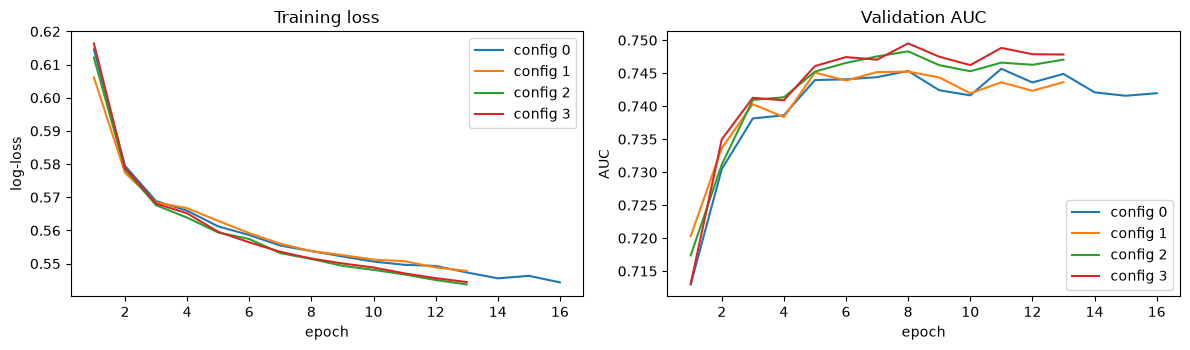

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for i, r in enumerate(search):
    h = pd.DataFrame(r["history"])
    axes[0].plot(h.epoch, h.train_loss, label=f"config {i}")
    axes[1].plot(h.epoch, h.val_auc, label=f"config {i}")
axes[0].set(title="Training loss", xlabel="epoch", ylabel="log-loss")
axes[1].set(title="Validation AUC", xlabel="epoch", ylabel="AUC")
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

Training loss keeps falling while validation AUC levels off. That gap is overfitting, and it is why we stop early.

## 5 · Refit on all training students, then score the test students once

BKT was fitted on all training students, so DKT gets the same data: retrain from scratch with the chosen settings for the chosen number of epochs.

In [11]:
model, optimiser, rng = new_model(BEST_CFG)
train_batches = make_batches(to_sequences(train))
for epoch in range(BEST_EPOCH):
    train_epoch(model, optimiser, train_batches, rng)
assert_no_leak(model)

test_batches = make_batches(to_sequences(test))
test_preds["DKT (LSTM)"] = predict_dkt(model, test_batches, len(test))
results_df = pd.DataFrame([evaluate(y_test, p, name) for name, p in test_preds.items()]).round(4)
results_df

,model,auc,rmse,acc,logloss
0,global mean,0.5000,0.4770,0.6506,0.6475
1,per-skill mean,0.6198,0.4668,0.6577,0.6260
2,"BKT (NumPy, from scratch)",0.7195,0.4404,0.7115,0.5727
3,DKT (LSTM),0.7513,0.4301,0.7230,0.5505


### Is the difference from BKT real?
Answers from one student are related, so we bootstrap **students**, not rows: resample the test students 1,000 times and recompute both AUCs on each sample. If the 95% interval of the difference excludes 0, the gap is unlikely to come from which students happened to be in the test set. It does not cover variation between random seeds.

In [12]:
rows_by_student = list(test.groupby("user_id", sort=False).indices.values())
p_b, p_d = test_preds["BKT (NumPy, from scratch)"], test_preds["DKT (LSTM)"]
boot_rng, diffs = np.random.default_rng(SEED), []
for _ in range(1000):
    pick = boot_rng.integers(0, len(rows_by_student), len(rows_by_student))
    r = np.concatenate([rows_by_student[j] for j in pick])
    diffs.append(roc_auc_score(y_test[r], p_d[r]) - roc_auc_score(y_test[r], p_b[r]))
AUC_DIFF = float(roc_auc_score(y_test, p_d) - roc_auc_score(y_test, p_b))
CI_LOW, CI_HIGH = map(float, np.percentile(diffs, [2.5, 97.5]))
print(f"DKT - BKT AUC = {AUC_DIFF:+.4f}, 95% CI [{CI_LOW:+.4f}, {CI_HIGH:+.4f}]")

DKT - BKT AUC = +0.0317, 95% CI [+0.0258, +0.0377]


### Where does each model do well?
In ASSISTments students usually answer many questions on one skill in a row. Your pilot students will start cold and change topic more often, so the rows that resemble the pilot are *first answer overall*, *first time on a skill* and *skill switch*.

In [13]:
previous = test.groupby("user_id").skill_name.shift()
groups = {
    "all rows": np.ones(len(test), bool),
    "first answer overall": previous.isna().values,
    "first time on a skill": ~test.duplicated(["user_id", "skill_name"]).values,
    "skill switch": (previous.notna() & (previous != test.skill_name)).values,
    "same skill as previous answer": (previous == test.skill_name).values,
}
segments_df = pd.DataFrame([
    dict(rows=name, n=int(m.sum()),
         per_skill_mean=roc_auc_score(y_test[m], test_preds["per-skill mean"][m]),
         bkt=roc_auc_score(y_test[m], p_b[m]),
         dkt=roc_auc_score(y_test[m], p_d[m]))
    for name, m in groups.items()]).round(4)
segments_df

,rows,n,per_skill_mean,bkt,dkt
0,all rows,52128,0.6198,0.7195,0.7513
1,first answer overall,828,0.6287,0.6502,0.6472
2,first time on a skill,7168,0.6347,0.6542,0.7239
3,skill switch,12715,0.6360,0.6833,0.7300
4,same skill as previous answer,38585,0.6155,0.7319,0.7588


## 6 · Can this model choose questions?

A good AUC does not make a good tutor, so both models get the same checks:

1. **Wrong direction:** after a correct answer on a skill, does the estimate for that skill go *down* (or up after a wrong one)? DKT has no constraint against this (Yeung & Yeung, 2018). BKT can do it too: its *learn* step is added after every answer, including wrong ones.
2. **Can it reach 0.95?** For a new student who gets 20 in a row right on one skill. The 0.95 rule was designed for BKT's P(known), whereas DKT outputs P(correct), which is a different quantity.
3. **Does failure lower it?** For a new student who gets 20 in a row wrong, is the estimate lower than at the start?
4. **Is the bar too low?** How many skills count as mastered before any answer, or after two or fewer right answers?

BKT is judged on P(known) and DKT on P(correct), because those are what a policy would read from each.

,BKT P(known),DKT P(correct)
wrong_direction_rate,0.008,0.109
skills_reaching_095,1.000,0.111
median_best_in_20_right,1.000,0.874
skills_not_lower_after_20_wrong,0.189,0.189
skills_095_before_any_answer,0.100,0.000
skills_095_within_2_right,0.789,0.044


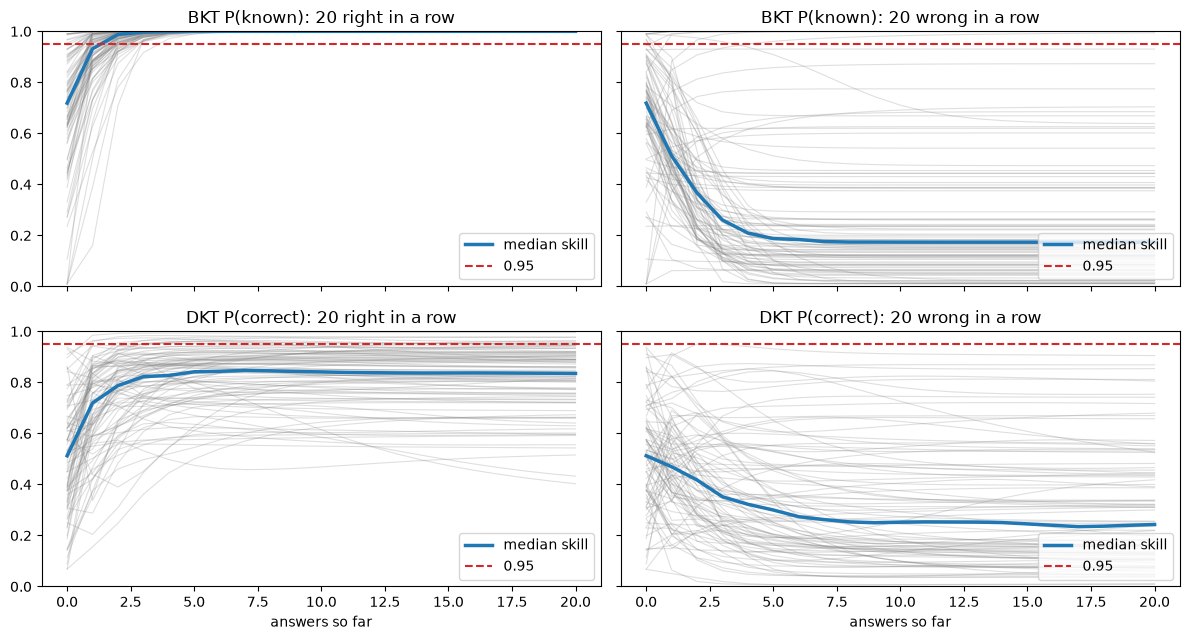

In [14]:
@torch.no_grad()
def behaviour(model):
    model.eval()
    wrong = n = 0
    for b in test_batches:
        p = torch.sigmoid(model(b["inputs"]))
        before = p[:, :-1].gather(2, b["skills"][:, :-1, None]).squeeze(-1)
        after = p[:, 1:].gather(2, b["skills"][:, :-1, None]).squeeze(-1)
        real = b["mask"][:, 1:]
        was_right = b["answers"][:, :-1] == 1
        bad = torch.where(was_right, after < before, after > before)
        wrong += int(bad[real].sum()); n += int(real.sum())

    streak = {}
    for correct in (0, 1):
        x = torch.tensor([[0] + [1 + 2 * k + correct] * 20 for k in range(K)])
        p = torch.sigmoid(model(x))
        streak[correct] = p[torch.arange(K), :, torch.arange(K)].numpy()   # skills x (21 positions)
    return summarise(wrong / n, streak), streak

def behaviour_bkt():
    p_known, wrong, n = {}, 0, 0
    seen = test.groupby("user_id").cumcount(ascending=False).values    # 0 = student's last answer
    for user, skill, correct, left in zip(test.user_id, test.skill_name, test.correct, seen):
        p = bkt_params[skill]
        k = p_known.get((user, skill), p["prior"])
        k_next = bkt_step(k, correct, p)
        p_known[user, skill] = k_next
        if left:                                         # same rows as DKT: answers that have a successor
            wrong += (k_next < k) if correct else (k_next > k)
            n += 1
    streak = {c: np.empty((K, 21)) for c in (0, 1)}
    for i, skill in enumerate(SKILLS):
        for c in (0, 1):
            streak[c][i, 0] = bkt_params[skill]["prior"]
            for t in range(20):
                streak[c][i, t + 1] = bkt_step(streak[c][i, t], c, bkt_params[skill])
    return summarise(wrong / n, streak), streak

def bkt_step(k, correct, p):
    p_c = k * (1 - p["slip"]) + (1 - k) * p["guess"]
    post = k * (1 - p["slip"]) / p_c if correct else k * p["slip"] / (1 - p_c)
    return post + (1 - post) * p["learn"]

def summarise(wrong_rate, streak):
    return dict(
        wrong_direction_rate=float(wrong_rate),
        skills_reaching_095=float((streak[1].max(1) >= 0.95).mean()),
        median_best_in_20_right=float(np.median(streak[1].max(1))),
        skills_not_lower_after_20_wrong=float((streak[0][:, -1] >= streak[0][:, 0]).mean()),
        skills_095_before_any_answer=float((streak[1][:, 0] >= 0.95).mean()),
        skills_095_within_2_right=float((streak[1][:, :3].max(1) >= 0.95).mean()),
    )

BEHAVIOUR, streak = behaviour(model)
BEHAVIOUR_BKT, streak_bkt = behaviour_bkt()
display(pd.DataFrame({"BKT P(known)": BEHAVIOUR_BKT, "DKT P(correct)": BEHAVIOUR}).round(3))

fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True, sharey=True)
for row, (name, st) in enumerate((("BKT P(known)", streak_bkt), ("DKT P(correct)", streak))):
    for ax, correct, title in zip(axes[row], (1, 0), ("20 right in a row", "20 wrong in a row")):
        ax.plot(st[correct].T, color="grey", alpha=0.25, lw=0.8)
        ax.plot(np.median(st[correct], 0), color="C0", lw=2.5, label="median skill")
        ax.axhline(0.95, color="C3", ls="--", label="0.95")
        ax.set(title=f"{name}: {title}", ylim=(0, 1)); ax.legend(loc="lower right")
for ax in axes[1]: ax.set_xlabel("answers so far")
plt.tight_layout(); plt.show()

**What this means for the app:** don't put DKT's output straight into the `p_known >= 0.95` policy. Storing `p_dkt` for the AUC comparison is safe. To *drive* questions with DKT you need its own threshold (chosen before the pilot, without the test students) and a cap on questions per topic, so that nobody gets stuck.

Read the BKT column before week 5 as well. The last two rows show how often parameters learned on US middle-school students would declare a topic mastered with little or no evidence from a Nigerian student. A minimum number of questions per topic guards against that.

## 7 · Export for FastAPI

`artifacts/dkt/` gets three files:

- `dkt.onnx`: the network and weights. It runs on `onnxruntime`, which is far smaller than PyTorch.
- `dkt_meta.json`: skill order, input encoding, checksum, metrics and test vectors.
- `dkt_loader.py`: the loader below. It checks the checksum and replays the test vectors at start-up, so a bad file fails at boot and not during the pilot.

The service needs only `onnxruntime` and `numpy`:

```python
from dkt_loader import load_dkt
predict, meta = load_dkt("artifacts/dkt")        # once, at start-up
p = predict([("Venn Diagram", 1), ("Mean", 0)])  # {skill: P(correct on the next question)}
predict([])                                      # a brand-new student
```

The loader speaks **ASSISTments skill names**. Translating WAEC/JAMB topics stays in the model service, through `topic_skill_map.csv`. For `p_dkt`, call it with the history *before* the current answer.

In [15]:
def load_dkt(directory):
    """Load the exported DKT. Returns (predict, meta). Needs only numpy and onnxruntime."""
    import hashlib
    import json
    from pathlib import Path

    import numpy as np
    import onnxruntime as ort

    directory = Path(directory)
    meta = json.loads((directory / "dkt_meta.json").read_text(encoding="utf-8"))
    blob = (directory / meta["model_file"]).read_bytes()
    if hashlib.sha256(blob).hexdigest() != meta["model_sha256"]:
        raise ValueError("DKT model and metadata do not match: export them again")

    options = ort.SessionOptions()
    options.intra_op_num_threads = 1  # one student at a time: more threads don't help
    session = ort.InferenceSession(blob, options, providers=["CPUExecutionProvider"])
    skills = meta["skills"]
    index = {skill: i for i, skill in enumerate(skills)}

    def predict(history):
        """history: [(skill_name, correct), ...], oldest first. An unknown skill raises KeyError."""
        ids = [0]  # START
        for skill, correct in history:
            if correct not in (0, 1):
                raise ValueError(f"correct must be 0 or 1, got {correct!r}")
            ids.append(1 + 2 * index[skill] + int(correct))
        probs = session.run(["p_correct"], {"interactions": np.array([ids], dtype=np.int64)})[0][0]
        return {skill: float(p) for skill, p in zip(skills, probs)}

    for case in meta["test_vectors"]:
        got = predict(case["history"])
        if not np.allclose([got[s] for s in skills], case["p_correct"], atol=1e-4, rtol=0):
            raise ValueError("DKT test vector failed: the runtime gives different predictions")

    return predict, meta

In [16]:
class NextAnswer(nn.Module):
    """What the service needs: one student in, P(correct) for every skill on the NEXT question out."""
    def __init__(self, dkt):
        super().__init__()
        self.dkt = dkt

    def forward(self, interactions):
        return torch.sigmoid(self.dkt(interactions)[:, -1])

# Build in a staging folder, so a failed export never replaces a working one.
staging = OUT_DIR.with_name(OUT_DIR.name + ".staging")
shutil.rmtree(staging, ignore_errors=True)
staging.mkdir(parents=True)

next_answer = NextAnswer(model).eval()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")                      # exporter deprecation chatter
    torch.onnx.export(next_answer, (torch.zeros((1, 5), dtype=torch.long),), str(staging / "dkt.onnx"),
                      input_names=["interactions"], output_names=["p_correct"],
                      dynamic_shapes={"interactions": {1: torch.export.Dim("length", min=1)}},
                      dynamo=True, external_data=False, verbose=False)

# The exporter embeds stack traces (your local paths and username) in every node. Strip them: the file
# gets shared, and without them identical training runs give an identical version hash.
proto = onnx.load(str(staging / "dkt.onnx"))
for item in [proto.graph, *proto.graph.node, *proto.graph.value_info, *proto.graph.initializer,
             *proto.graph.input, *proto.graph.output]:
    del item.metadata_props[:]
onnx.save(proto, str(staging / "dkt.onnx"))
onnx.checker.check_model(str(staging / "dkt.onnx"))

# Made-up histories, so that no student data ends up in the exported file.
histories = [[], [(SKILLS[0], 1)], [(SKILLS[i % K], int(i % 3 != 0)) for i in range(60)]]
vectors = []
for h in histories:
    ids = torch.tensor([[0] + [1 + 2 * SKILL_TO_IDX[s] + c for s, c in h]])
    with torch.no_grad():
        vectors.append(dict(history=h, p_correct=next_answer(ids)[0].tolist()))

MODEL_SHA256 = hashlib.sha256((staging / "dkt.onnx").read_bytes()).hexdigest()
meta = dict(
    model="DKT", format_version=1, version=MODEL_SHA256[:12], mlflow_run_id=PARENT_RUN_ID,
    trained_on="ASSISTments 2009", data_sha256=DATA_SHA256, test_students_sha256=SPLIT_SHA256,
    model_file="dkt.onnx", model_sha256=MODEL_SHA256,
    input_encoding="[0] + [1 + 2*skill_index + correct for each past answer, oldest first]",
    output="P(correct on the next question) per skill. This is NOT P(known).",
    skills=SKILLS, config=BEST_CFG, epochs=BEST_EPOCH, seed=SEED,
    test_metrics={k: float(v) for k, v in evaluate(y_test, p_d, "dkt").items() if k != "model"},
    behaviour=BEHAVIOUR, test_vectors=vectors,
)
(staging / "dkt_meta.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
(staging / "dkt_loader.py").write_text(
    '"""Generated by ml/03_dkt.ipynb. Edit the notebook, not this file."""\n\n\n' + inspect.getsource(load_dkt),
    encoding="utf-8")
print(f"exported version {meta['version']} ({(staging / 'dkt.onnx').stat().st_size / 1024:.0f} KB)")

exported version 8d7a7c976b57 (1197 KB)


### Does the export give the numbers we evaluated?
Replay test students through the **exported file** one answer at a time, as the app will, and compare with the predictions scored in §5.

In [17]:
predict, _ = load_dkt(staging)
test_skill, test_correct = test.skill_name.tolist(), test.correct.tolist()
by_length = sorted(rows_by_student, key=len)
sample = by_length[::40] + [by_length[-1]]               # short to long, plus the longest
worst, checked, t0 = 0.0, 0, time.time()
for rows in sample:
    history = []
    for r in rows:
        worst = max(worst, abs(predict(history)[test_skill[r]] - p_d[r]))
        history.append((test_skill[r], test_correct[r]))
        checked += 1
assert worst < 1e-4, f"export differs from PyTorch by {worst}"
print(f"{checked:,} predictions replayed | largest difference {worst:.1e} | "
      f"{(time.time() - t0) / checked * 1000:.1f} ms per call")

OUT_DIR.mkdir(parents=True, exist_ok=True)
for f in staging.iterdir():
    f.replace(OUT_DIR / f.name)
staging.rmdir()
results_df.to_csv(OUT_DIR / "results.csv", index=False)
segments_df.to_csv(OUT_DIR / "results_by_segment.csv", index=False)
print("wrote", ", ".join(sorted(f.name for f in OUT_DIR.iterdir())))

1,982 predictions replayed | largest difference 1.8e-07 | 5.0 ms per call
wrote dkt.onnx, dkt_loader.py, dkt_meta.json, results.csv, results_by_segment.csv


## 8 · Log and register in MLflow
To browse the runs, from `ml/`: `mlflow ui --backend-store-uri sqlite:///mlflow.db`

In [18]:
from mlflow.models import ModelSignature
from mlflow.types import Schema, TensorSpec

METRIC_KEYS = {"global mean": "global_mean", "per-skill mean": "skill_mean",
               "BKT (NumPy, from scratch)": "bkt", "DKT (LSTM)": "dkt"}

with mlflow.start_run(run_id=PARENT_RUN_ID):
    mlflow.log_params(dict(
        BEST_CFG, epochs=BEST_EPOCH, seed=SEED, batch_size=BATCH_SIZE, dataset="assist09",
        test_fraction=TEST_FRACTION, val_fraction=VAL_FRACTION, min_interactions=MIN_INTERACTIONS_PER_SKILL,
        n_skills=K, data_sha256=DATA_SHA256, test_students_sha256=SPLIT_SHA256,
        preprocessing="non-null skill_name; original==1; correct in 0/1; dedupe order_id+skill_name; "
                      "skills>=50 rows; sort order_id; collapsed multi-skill keeps one name"))
    for name, p in test_preds.items():
        m = evaluate(y_test, p, name)
        mlflow.log_metrics({f"{k}__{METRIC_KEYS[name]}": float(v) for k, v in m.items() if k != "model"})
    mlflow.log_metrics({f"{k}__bkt": v for k, v in BEHAVIOUR_BKT.items()})
    mlflow.log_metrics(dict({f"{k}__dkt": v for k, v in BEHAVIOUR.items()}, val_auc=chosen["best"]["auc"], auc_diff_dkt_bkt=AUC_DIFF,
                            auc_diff_ci_low=CI_LOW, auc_diff_ci_high=CI_HIGH))
    mlflow.log_artifacts(str(OUT_DIR), artifact_path="export")   # the folder the service loads
    info = mlflow.onnx.log_model(
        onnx.load(str(OUT_DIR / "dkt.onnx")), name="model", registered_model_name=REGISTERED_NAME,
        save_as_external_data=False,
        pip_requirements=[f"onnxruntime=={onnxruntime.__version__}", f"numpy=={np.__version__}"],
        signature=ModelSignature(inputs=Schema([TensorSpec(np.dtype("int64"), (1, -1), "interactions")]),
                                 outputs=Schema([TensorSpec(np.dtype("float32"), (1, K), "p_correct")])))

client = mlflow.MlflowClient()
client.set_model_version_tag(REGISTERED_NAME, info.registered_model_version, "export_version", meta["version"])
print(f"registered {REGISTERED_NAME} v{info.registered_model_version} (export {meta['version']})")

registered dkt-assist09 v1 (export 8d7a7c976b57)


Successfully registered model 'dkt-assist09'.
Created version '1' of model 'dkt-assist09'.


## Limits, and next steps

- **This is not yet evidence about Nigerian students.** It shows how well DKT predicts unseen *ASSISTments* students. RQ1 is answered by the AUC of `attempts.p_bkt` and `attempts.p_dkt` from the pilot.
- **Curriculum gap.** ASSISTments 2009 is mostly middle-school maths. Of the ten seeded topics, *Number Bases* and *Trigonometry* have no real equivalent among these skills (Pythagorean Theorem is only a prerequisite), logarithms have none, and *Quadratic Equations* and *Sequences and Series* have only weak proxies (Polynomial Factors, Pattern Finding). Settle this in notebook 02 before relying on either model for those topics.
- **One topic maps to several skills.** Averaging works for output. For DKT *input*, decide how one answer on a topic becomes history (one representative skill, or one event per mapped skill). The second choice inflates the history, so test it.
- **Serving.** Docker builds the model service from `services/model/`, so it cannot see `ml/artifacts/`. In weeks 6–7 either mount the export folder or download the `export` artifact of the registered version's run.
- **Reproducibility.** The same CPU and package versions give the same result. Other machines will differ slightly.